# M2 — measured full-dataset results

This notebook presents actual outputs from **`results/m2/full/20261114_full`**. It does not retrain
models or retune test results. The full implementation and 20-section explanation
are in `M2_walkthrough.ipynb`; section-by-section report prose is in `M2_report.md`.
All three variants were frozen using validation data before one final test batch.

**Selected by validation AP50:** M2-C.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
roots=[Path.cwd(),*Path.cwd().parents]
ROOT=next(p for base in roots for p in [base,base/"Comp9517-bird-detection"]
          if (p/"m2_ml/detector.py").exists())
RUN=ROOT/'results/m2/full/20261114_full'
manifest=json.loads((RUN/"manifest.json").read_text())
display(Markdown("**Run:** `"+str(RUN)+"`"))

**Run:** `/Users/apple/Desktop/COMP9517 group project/Comp9517-bird-detection/results/m2/full/20261114_full`

## 1. Dataset and leakage checks

Training uses every original training image. Validation selects settings and the
final variant. The held-out test is evaluated after selection is frozen. No crops
move between splits. The manifest's source-group audit checks the supplied split.

In [2]:
display(pd.DataFrame(json.loads((RUN/"data_audit.json").read_text())["splits"]))
display(pd.DataFrame([manifest["training_crop_counts"]]))
print("Training images:",len(manifest["train_images"]))
print("Validation images:",len(manifest["validation_images"]))
print("Test images:",len(manifest["test_images"]))
print("Window templates:",manifest["templates"])
print("Candidate recall:",manifest["proposal_diagnostic"])

,split,images,bird_boxes,negative_images
0,train,1369,8663,154
1,val,291,1843,33


,positive,negative
0,8663,32856


Training images: 1369
Validation images: 291
Test images: 240
Window templates: [[12, 11], [21, 20], [38, 27], [29, 43], [58, 45], [65, 86], [114, 68], [141, 130], [270, 222]]
Candidate recall: {'recall': 0.956592512208356, 'covered_boxes': 1763, 'total_boxes': 1843}


## 2. How the detector works

Bird and background crops become fixed-size 32 × 32 patches. HOG describes edge
directions in 1,764 numbers. Optional HSV histograms add 24 colour numbers. A
training-fitted standardiser and linear SVM turn those features into a bird score.
The detector slides training-derived templates across each image, then NMS removes
duplicate boxes. M2-C refits the model with confusing background examples mined
from a fixed 160-image training subset. Both original classes of samples are retained.

Shared features and vectorised HOG accelerate the same descriptor calculation;
tests compare against reference HOG and independent model scoring.

In [3]:
frozen=json.loads((RUN/"FROZEN_SELECTION.json").read_text())
display(pd.DataFrame(frozen["configs"]).T)
print("Mining source:",manifest["mining_source"])
print("Mined negative samples:",manifest["hard_negative_count"])
print("Matched-postprocessing mined-model metrics:",manifest["matched_mining_metrics"])

,seed,patch_size,orientations,cell_size,block_cells,hog_backend,hsv_bins,n_templates,stride_fraction,min_stride,...,negative_coverage,max_positives,C,batch_size,score_floor,nms_iou,pre_nms_topk,max_detections,hard_negatives_per_image,max_hard_negatives
M2-A,42,32,9,4,2,vectorized,8,9,0.25,2,...,0.1,12000,0.1,256,-2.0,0.5,5000,300,12,6000
M2-B,42,32,9,4,2,vectorized,8,9,0.25,2,...,0.1,12000,1.0,256,-2.0,0.5,5000,300,12,6000
M2-C,42,32,9,4,2,vectorized,8,9,0.25,2,...,0.1,12000,1.0,256,-2.0,0.5,5000,300,12,6000


Mining source: M2-B
Mined negative samples: 1920
Matched-postprocessing mined-model metrics: {'AP50': 0.04479260861049132, 'AP50_95': 0.011448495341811294, 'AP50_small': 0.015966244591526475, 'AP50_medium': 0.07500587908152637, 'AP50_large': 0.10443269896035}


## 3. Validation and final-test results

AP50 is the project's mAP@0.5 metric for one class. AP50–95 tests stricter box
alignment. Small/medium/large AP50 use COCO area bins. The final variant is chosen
from validation AP50; the test table is a final comparison of already-frozen models.

**Validation: 291 images**

,variant,AP50,AP50_95,AP50_small,AP50_medium,AP50_large
0,M2-A,0.0171,0.0040,0.0050,0.0386,0.1010
1,M2-B,0.0172,0.0039,0.0043,0.0397,0.1099
2,M2-C,0.0448,0.0114,0.0160,0.0750,0.1044


**Final test: 240 images**

,variant,AP50,AP50_95,AP50_small,AP50_medium,AP50_large
0,M2-A,0.0122,0.0030,0.0088,0.0215,0.1028
1,M2-B,0.0153,0.0036,0.0116,0.0260,0.0978
2,M2-C,0.0296,0.0071,0.0243,0.0322,0.1198


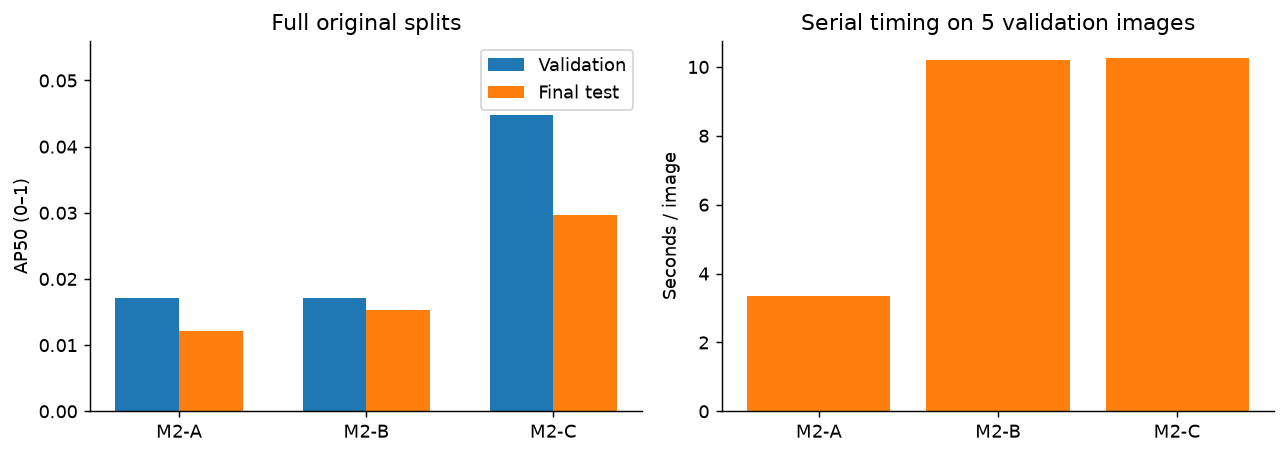

In [4]:
val=pd.read_csv(RUN/"validation_summary.csv")
test=pd.read_csv(RUN/"test_summary.csv")
columns=["variant","AP50","AP50_95","AP50_small","AP50_medium","AP50_large"]
display(Markdown("**Validation: 291 images**"));display(val[columns].round(4))
display(Markdown("**Final test: 240 images**"));display(test[columns].round(4))
display(Image(filename=str(RUN/"m2_comparison.png")))

## 4. Timing boundaries

Training time includes shared paired feature preparation and selected fitting;
M2-C adds source fitting, eight-process mining wall time and refitting. Validation
search is separate. The original HOG-only variant is charged the same paired
preparation cost, so this is an experimental-pipeline time.

Standalone inference was timed in serial on the same five randomly selected
validation images for each model, with no concurrent workers and one numerical
library thread. It includes image loading through NMS and prediction construction,
and excludes model loading, disk output and evaluation. These are five-image
validation latency estimates, not timing measurements across all test images.

In [5]:
display(val[["variant","training_pipeline_seconds","svm_fit_seconds",
             "mean_inference_seconds","median_inference_seconds","timed_images"]].round(3))
display(pd.read_csv(RUN/"serial_inference_times.csv").round(3))
print("Software environment:",manifest["environment"])

,variant,training_pipeline_seconds,svm_fit_seconds,mean_inference_seconds,median_inference_seconds,timed_images
0,M2-A,26.010,13.895,3.335,3.291,5
1,M2-B,25.861,13.746,10.214,10.261,5
2,M2-C,469.319,16.524,10.247,10.253,5


,variant,image_id,seconds
0,M2-A,beach_bird_1395,3.498
1,M2-A,beach_bird_1496,3.240
2,M2-A,beach_bird_1497,3.234
3,M2-A,beach_bird_1559,3.410
4,M2-A,beach_bird_1592,3.291
5,M2-B,beach_bird_1395,10.283
6,M2-B,beach_bird_1496,10.030
7,M2-B,beach_bird_1497,10.048
8,M2-B,beach_bird_1559,10.261
9,M2-B,beach_bird_1592,10.449


Software environment: {'python': '3.12.14', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'processor': 'arm', 'packages': {'numpy': '2.5.4', 'Pillow': '13.0.0', 'scikit-image': '0.26.0', 'scikit-learn': '1.9.1', 'pycocotools': '2.0.11', 'joblib': '1.6.0'}}


### Why good crop classification does not imply good detection

This supplementary diagnostic uses ground-truth-localised positive crops and
randomly sampled backgrounds. Models are only scored, not refitted. These crop
ROC/AP/accuracy values describe a different, easier task than image detection;
they must not be reported as detector AP. Full search exposes many more difficult
backgrounds and imperfectly aligned candidate windows.

In [6]:
crop=pd.read_csv(RUN/"crop_classification_diagnostic.csv")
display(crop[(crop.crop_split=="val") & crop.model.isin(["M2-A","M2-B","M2-C"])].round(4))

,model,crop_split,positive_crops,negative_crops,ROC_AUC,crop_average_precision,balanced_accuracy_at_zero
8,M2-A,val,1843,6984,0.9405,0.8429,0.8707
9,M2-B,val,1843,6984,0.9398,0.8389,0.8679
10,M2-C,val,1843,6984,0.9335,0.8415,0.8586


### Candidate coverage after ranking and NMS

The original search covers 95.66% of validation annotations at IoU 0.5. The table
below measures geometric coverage after each model's score floor/candidate cap
and after NMS. Coverage allows one candidate to overlap more than one annotation;
it is a diagnostic, not confidence-thresholded one-to-one recall or AP. All models
hit the 5,000-candidate cap on every validation image in this run.

In [7]:
display(pd.read_csv(RUN/"candidate_retention_diagnostic.csv").round(4))

,variant,images,candidate_cap_images,bird_boxes,retained_candidate_recall,postNMS_geometric_recall
0,M2-A,291,291,1843,0.8969,0.5534
1,M2-B,291,291,1843,0.9012,0.5513
2,M2-C,291,291,1843,0.9067,0.5741


## 5. Small objects, dense scenes and counting

Density results report sample sizes; the 51+ test group is tiny. AP is undefined
for no-bird images. Supplementary precision/recall/F1 and counting MAE use a
validation-selected margin threshold frozen for each model before testing. That
threshold is distinct from the lower AP candidate floor.

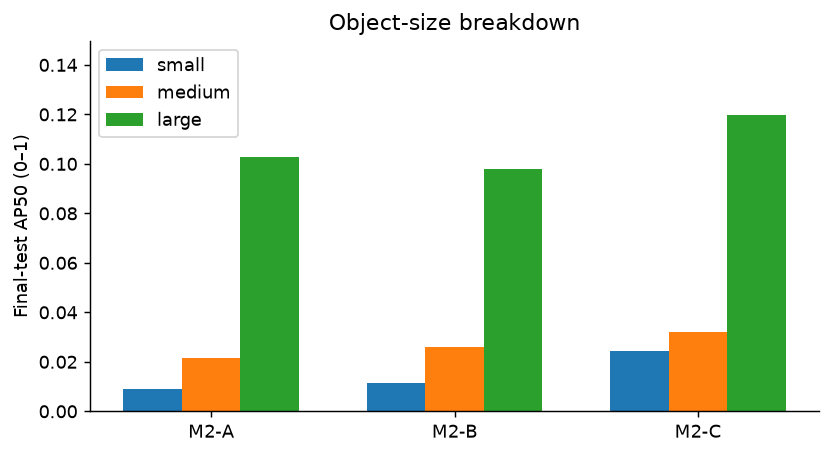

,variant,density,images,bird_boxes,AP50,AP50_95,AP50_small,AP50_medium,AP50_large
10,M2-C,0,27,0,NaN,NaN,NaN,NaN,NaN
11,M2-C,1-5,135,319,0.0337,0.0084,0.0157,0.0398,0.1692
12,M2-C,6-20,63,691,0.0378,0.0093,0.0311,0.0445,0.1084
13,M2-C,21-50,13,386,0.0725,0.0167,0.1110,0.0512,NaN
14,M2-C,51+,2,122,0.1270,0.0343,0.0954,0.2489,NaN


,variant,operating_score_floor,precision,recall,F1,count_MAE
0,M2-A,2.5,0.0360,0.0942,0.0521,16.5458
1,M2-B,2.5,0.0443,0.1080,0.0628,14.8250
2,M2-C,1.5,0.1042,0.0685,0.0827,6.2000


In [8]:
display(Image(filename=str(RUN/"m2_size_analysis.png")))
density=pd.read_csv(RUN/"test_density.csv")
display(density[density.variant==manifest["selected_variant"]].round(4))
display(test[["variant","operating_score_floor","precision","recall","F1","count_MAE"]].round(4))

## 6. Fixed-distortion robustness

The exact same 20 validation images are used for clean, Gaussian blur (radius 1
pixel) and brightness ×0.6 versions. Models, labels and thresholds stay fixed.
This is a small stress test with one severity, not a broad robustness guarantee.

,variant,distortion,images,AP50,AP50_95,AP50_small,AP50_medium,AP50_large
0,M2-A,clean,20,0.0113,0.0021,0.0044,0.0328,0.0477
1,M2-B,clean,20,0.0131,0.0024,0.0040,0.0365,0.0687
2,M2-C,clean,20,0.0259,0.0057,0.0323,0.0495,0.0347
3,M2-A,blur_sigma1,20,0.0129,0.0023,0.0117,0.0383,0.0350
4,M2-B,blur_sigma1,20,0.0157,0.0028,0.0116,0.0479,0.0360
5,M2-C,blur_sigma1,20,0.0331,0.0074,0.0563,0.0470,0.0503
6,M2-A,brightness_0.6,20,0.0113,0.0028,0.0044,0.0303,0.0759
7,M2-B,brightness_0.6,20,0.0131,0.0035,0.0048,0.0383,0.0698
8,M2-C,brightness_0.6,20,0.0340,0.0089,0.0214,0.0692,0.0541


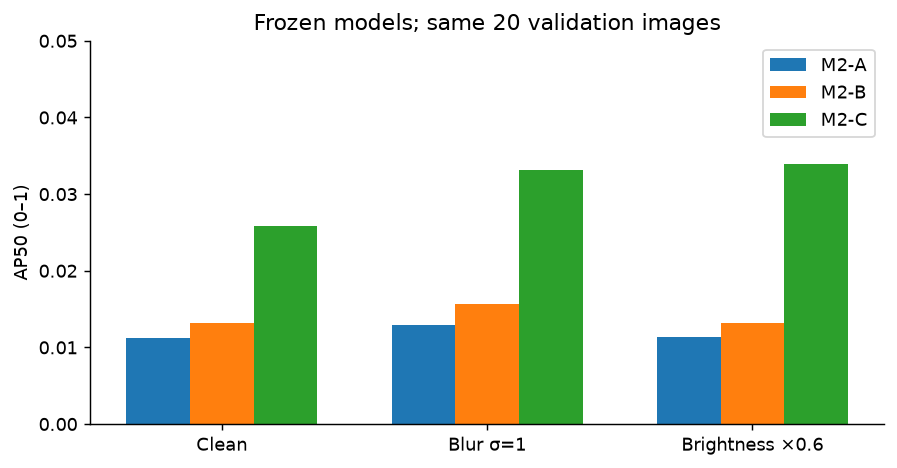

In [9]:
display(pd.read_csv(RUN/"robustness_summary.csv").round(4))
display(Image(filename=str(RUN/"m2_robustness.png")))

## 7. Successes and failures

Examples use explicit criteria: a positive image with at least one true detection
and the fewest errors, the most
missed birds among remaining images with at most 20 annotations, the negative
image with the most false alarms, and the densest flock.
They illustrate frozen final outputs and are not used to tune test settings.
Green dashed boxes are annotations; orange boxes are detections at the frozen operating
threshold. Read the TP/FP/FN counts alongside the image.

,role,image_id,ground_truth,predicted,TP,FP,FN,absolute_count_error,errors
0,Successful example,beach_bird_1816,1,1,1,0,0,0,0.0
1,Misses (at most 20 GT),beach_bird_1806,20,0,0,0,20,20,NaN
2,Negative-scene example,beach_bird_1829,0,38,0,38,0,38,NaN
3,Dense flock,beach_bird_1790,66,3,0,3,66,63,NaN


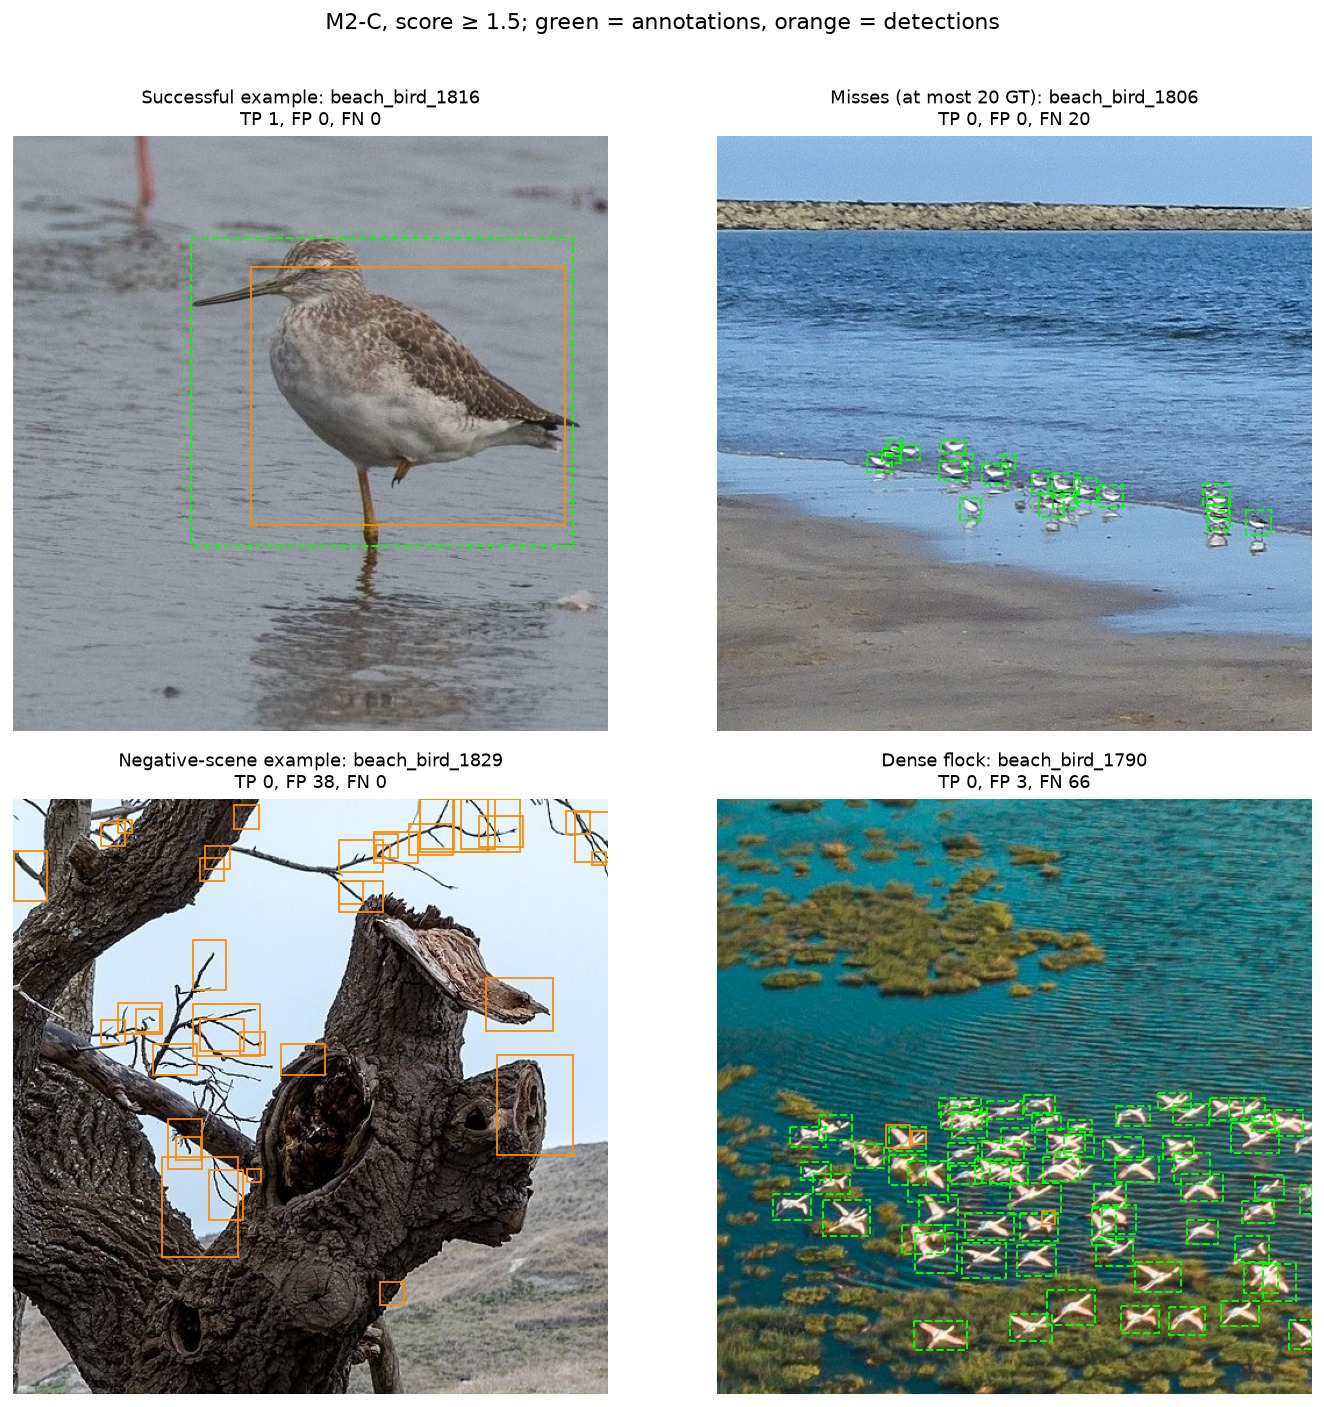

Visual inspection shows that `beach_bird_1816` contains a large, isolated bird that
is detected correctly at IoU 0.5, although the fixed template omits part of the
bill and lower extremities. In `beach_bird_1806`, the twenty birds occupy far fewer
pixels near the waterline, and none survives the frozen score threshold. The
negative scene `beach_bird_1829` produces 38 false detections, many on branches and
stump edges, illustrating confusion between background structure and the learned
appearance cues. In the dense flying flock `beach_bird_1790`, all 66 annotated
birds are missed at the same operating threshold, with three unmatched detections.
These observations are consistent with limited small-object detail, background
confusion and coarse localisation. They do not isolate which individual feature
or postprocessing stage causes every error. Counts refer to the frozen score
threshold of 1.5; AP also includes lower-scoring detections.


In [10]:
display(pd.read_csv(RUN/"qualitative_examples.csv"))
display(Image(filename=str(RUN/"m2_success_failure_examples.jpg")))
if (RUN/"visual_review.md").exists():
    display(Markdown((RUN/"visual_review.md").read_text()))

## 8. Requirements and rubric review

M2 supplies literature motivation, implemented methods, controlled comparisons,
AP50 and timing, successes and failures, discussion, limitations, references and
documented code. Robustness and size/density analyses add depth. These results do
not replace the group's M1/M3 comparison, IEEE two-column PDF assembly, video or
contribution requirements. See `M2_requirements_review.md` for the exact mapping.

The source-code submission must exclude datasets, trained weights and result
images. The group report limit is ten pages of main text excluding references.
Metrics are not the sole grading basis: the rubric emphasises soundness,
evaluation rigour and discussion. All claims in the report should match the
saved numbers and actual example images.

## 9. Reproduce or inspect the run

```bash
python -m pip install -r requirements-m2.txt
python -m unittest m2_ml.test_detector -v
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python -m m2_ml.run_full \
  --run-dir results/m2/full/NEW_RUN_NAME --workers 8 \
  --mining-images 160 --benchmark-images 5 --robustness-images 20
```

Use a new run name for an independent training experiment. Add `--test` only when
the validation-based protocol and settings are final. The completed run here
already contains final test results; inspecting or reformatting saved files does
not require running inference again. `protocol.json`, `manifest.json`,
`environment-lock.txt`, `FROZEN_SELECTION.json`, per-image predictions and timing
CSVs preserve evidence. The source-code tests and earlier synthetic checks do not
provide bird performance scores; all tables in this notebook use the real dataset.

References: [Dalal & Triggs](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf),
[scikit-image HOG](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog),
[LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html),
[StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).